In [ ]:

!pip install -q datasets pandas pyarrow

In [ ]:

from datasets import load_dataset
import pandas as pd

dataset = load_dataset(
    "fancyzhx/amazon_polarity",
    split="train",
    streaming=True
)

reviews = list(dataset.take(2000))

df = pd.DataFrame(reviews)

print("Total Reviews:", len(df))
display(df.head())


README.md:   0%|          | 0.00/6.81k [00:00<?, ?B/s]

Total Reviews: 2000


,label,title,content
0,1,Stuning even for the non-gamer,This sound track was beautiful! It paints the ...
1,1,The best soundtrack ever to anything.,I'm reading a lot of reviews saying that this ...
2,1,Amazing!,This soundtrack is my favorite music of all ti...
3,1,Excellent Soundtrack,I truly like this soundtrack and I enjoy video...
4,1,"Remember, Pull Your Jaw Off The Floor After He...","If you've played the game, you know how divine..."


In [ ]:

# Display first 5 reviews
display(df.head())

# Check dataset information
df.info()

# Check number of rows and columns
print("Dataset Shape:", df.shape)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate reviews
print("\nDuplicate Reviews:")
print(df.duplicated().sum())


,label,title,content
0,1,Stuning even for the non-gamer,This sound track was beautiful! It paints the ...
1,1,The best soundtrack ever to anything.,I'm reading a lot of reviews saying that this ...
2,1,Amazing!,This soundtrack is my favorite music of all ti...
3,1,Excellent Soundtrack,I truly like this soundtrack and I enjoy video...
4,1,"Remember, Pull Your Jaw Off The Floor After He...","If you've played the game, you know how divine..."


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    2000 non-null   int64 
 1   title    2000 non-null   object
 2   content  2000 non-null   object
dtypes: int64(1), object(2)
memory usage: 47.0+ KB
Dataset Shape: (2000, 3)

Missing Values:
label      0
title      0
content    0
dtype: int64

Duplicate Reviews:
0


In [ ]:

# Remove duplicate reviews
df = df.drop_duplicates().copy()

# Remove missing reviews
df = df.dropna(subset=["content"])

# Remove unnecessary spaces
df["content"] = df["content"].str.strip()

# Remove empty reviews
df = df[df["content"] != ""].copy()

# Convert numeric labels into sentiments
df["Sentiment"] = df["label"].map({
    0: "Negative",
    1: "Positive"
})

print("Cleaned Dataset Shape:", df.shape)

display(df.head())


Cleaned Dataset Shape: (2000, 4)


,label,title,content,Sentiment
0,1,Stuning even for the non-gamer,This sound track was beautiful! It paints the ...,Positive
1,1,The best soundtrack ever to anything.,I'm reading a lot of reviews saying that this ...,Positive
2,1,Amazing!,This soundtrack is my favorite music of all ti...,Positive
3,1,Excellent Soundtrack,I truly like this soundtrack and I enjoy video...,Positive
4,1,"Remember, Pull Your Jaw Off The Floor After He...","If you've played the game, you know how divine...",Positive


In [ ]:

# Count positive and negative reviews
sentiment_counts = df["Sentiment"].value_counts()

print("Sentiment Counts:")
print(sentiment_counts)

# Calculate percentages
sentiment_percentage = (
    df["Sentiment"]
    .value_counts(normalize=True)
    * 100
)

print("\nSentiment Percentages:")
print(sentiment_percentage.round(2))


Sentiment Counts:
Sentiment
Negative    1035
Positive     965
Name: count, dtype: int64

Sentiment Percentages:
Sentiment
Negative    51.75
Positive    48.25
Name: proportion, dtype: float64


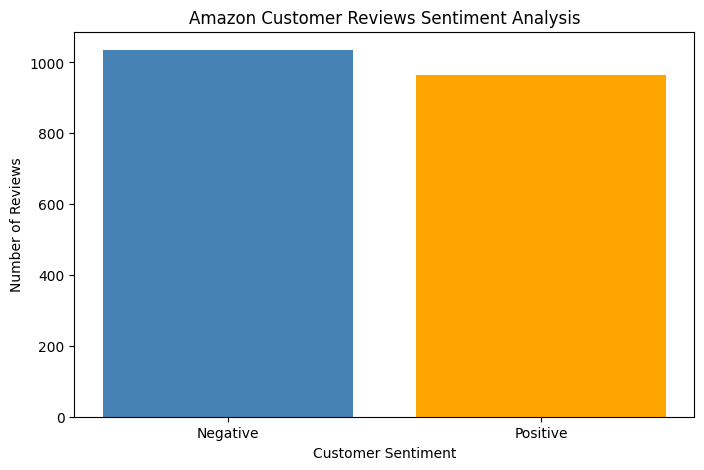

In [ ]:

import matplotlib.pyplot as plt

counts = df["Sentiment"].value_counts()

plt.figure(figsize=(8, 5))

plt.bar(
    counts.index,
    counts.values,
    color=["steelblue", "orange"]
)

plt.title("Amazon Customer Reviews Sentiment Analysis")
plt.xlabel("Customer Sentiment")
plt.ylabel("Number of Reviews")

plt.show()


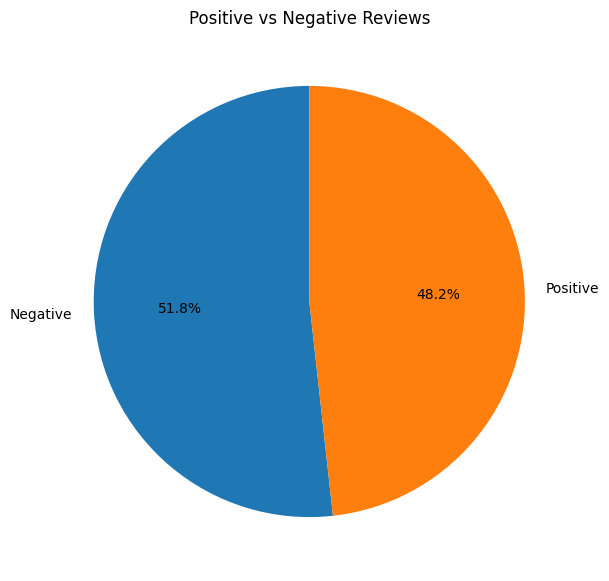

In [ ]:

plt.figure(figsize=(7, 7))

plt.pie(
    counts.values,
    labels=counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Positive vs Negative Reviews")
plt.show()


Average Review Length:
Sentiment
Negative    78.01
Positive    71.28
Name: Review_Length, dtype: float64


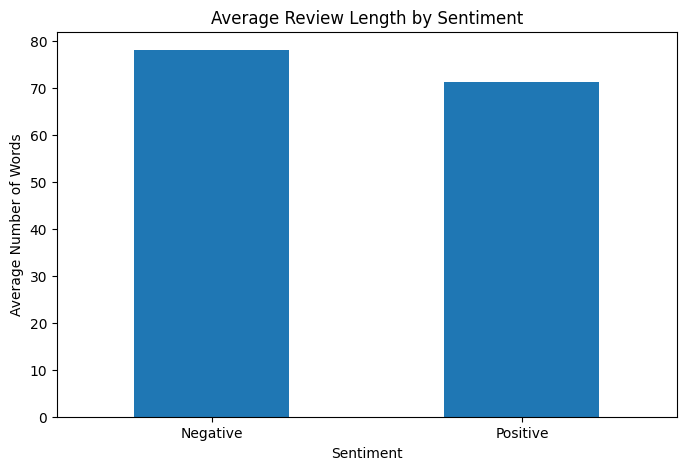

In [ ]:

# Count words in each review
df["Review_Length"] = (
    df["content"].str.split().str.len()
)

# Average review length by sentiment
avg_length = df.groupby(
    "Sentiment"
)["Review_Length"].mean()

print("Average Review Length:")
print(avg_length.round(2))

# Plot
avg_length.plot(
    kind="bar",
    figsize=(8, 5),
    title="Average Review Length by Sentiment"
)

plt.xlabel("Sentiment")
plt.ylabel("Average Number of Words")
plt.xticks(rotation=0)
plt.show()


In [ ]:

from google.colab import files

with pd.ExcelWriter(
    "Amazon_Reviews_Analysis.xlsx"
) as writer:

    df.to_excel(
        writer,
        sheet_name="Cleaned Reviews",
        index=False
    )

    sentiment_counts.rename(
        "Count"
    ).to_excel(
        writer,
        sheet_name="Sentiment Summary"
    )

    avg_length.rename(
        "Average Words"
    ).to_excel(
        writer,
        sheet_name="Review Length"
    )

files.download("Amazon_Reviews_Analysis.xlsx")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

!pip install -q nltk wordcloud


In [ ]:

import nltk
import re

from nltk.corpus import stopwords

nltk.download("stopwords")

stop_words = set(stopwords.words("english"))

# Keep negation words because they are important
# for understanding customer complaints.
stop_words -= {"no", "not", "nor"}

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z\s]", " ", text)

    words = text.split()

    words = [
        word for word in words
        if word not in stop_words and len(word) > 2
    ]

    return " ".join(words)

df["Cleaned_Review"] = df["content"].apply(clean_text)

display(df[["content", "Cleaned_Review"]].head())


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


,content,Cleaned_Review
0,This sound track was beautiful! It paints the ...,sound track beautiful paints senery mind well ...
1,I'm reading a lot of reviews saying that this ...,reading lot reviews saying best game soundtrac...
2,This soundtrack is my favorite music of all ti...,soundtrack favorite music time hands intense s...
3,I truly like this soundtrack and I enjoy video...,truly like soundtrack enjoy video game music p...
4,"If you've played the game, you know how divine...",played game know divine music every single son...


In [ ]:

from collections import Counter

negative_reviews = df[
    df["Sentiment"] == "Negative"
]

all_words = " ".join(
    negative_reviews["Cleaned_Review"]
).split()

word_counts = Counter(all_words)

top_words = pd.DataFrame(
    word_counts.most_common(15),
    columns=["Word", "Frequency"]
)

display(top_words)


,Word,Frequency
0,not,819
1,book,682
2,one,433
3,like,329
4,would,295
5,read,261
6,get,216
7,time,197
8,even,179
9,good,179


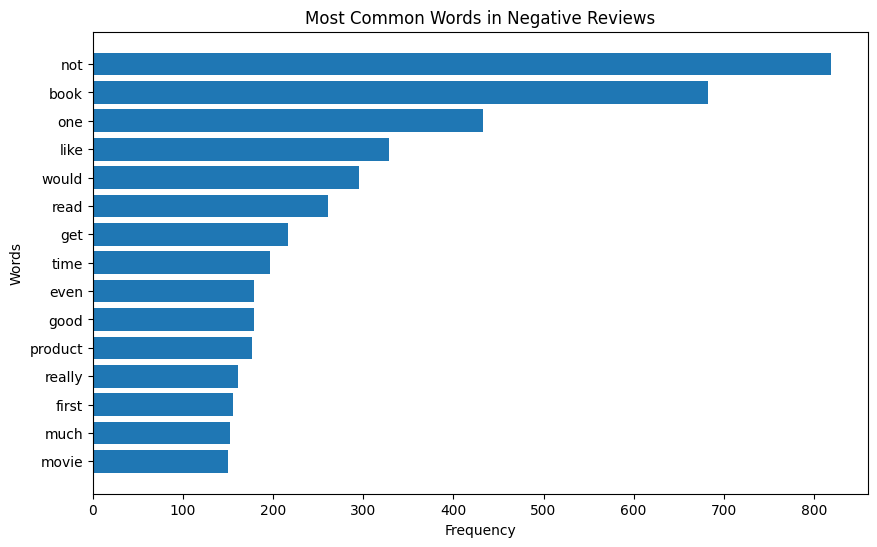

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    top_words["Word"],
    top_words["Frequency"]
)

plt.title("Most Common Words in Negative Reviews")
plt.xlabel("Frequency")
plt.ylabel("Words")
plt.gca().invert_yaxis()

plt.show()


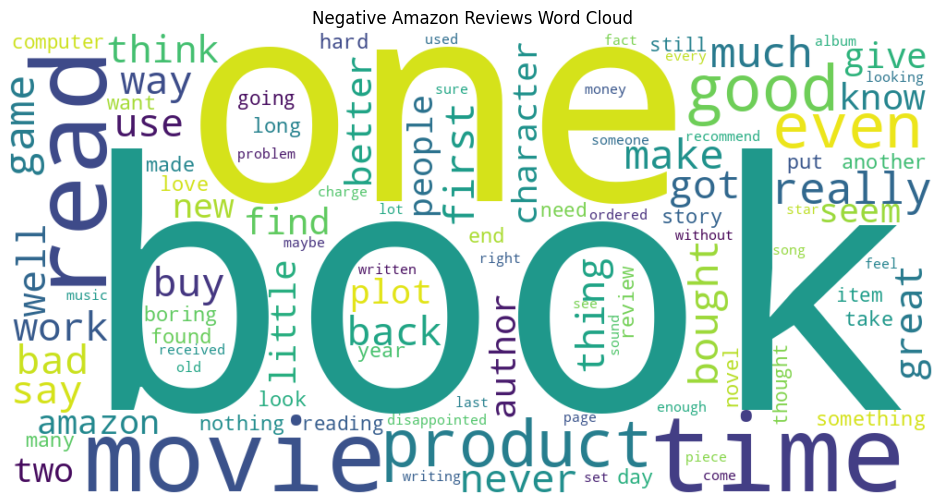

In [ ]:

from wordcloud import WordCloud

text = " ".join(
    negative_reviews["Cleaned_Review"]
)

wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color="white",
    max_words=100
).generate(text)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Negative Amazon Reviews Word Cloud")
plt.show()


In [ ]:

complaint_keywords = {
    "Quality": ["broken", "poor", "cheap", "defective"],
    "Delivery": ["late", "shipping", "delivery", "delayed"],
    "Price": ["expensive", "overpriced", "cost"],
    "Performance": ["slow", "failed", "stopped", "problem"],
    "Service": ["refund", "return", "support", "service"]
}

results = {}

for category, keywords in complaint_keywords.items():

    pattern = r"\b(?:" + "|".join(
        re.escape(word) for word in keywords
    ) + r")\b"

    count = negative_reviews[
        "Cleaned_Review"
    ].str.contains(
        pattern, regex=True, na=False
    ).sum()

    results[category] = count

complaints_df = pd.DataFrame(
    list(results.items()),
    columns=["Category", "Review Count"]
)

display(complaints_df)


,Category,Review Count
0,Quality,96
1,Delivery,23
2,Price,27
3,Performance,78
4,Service,87


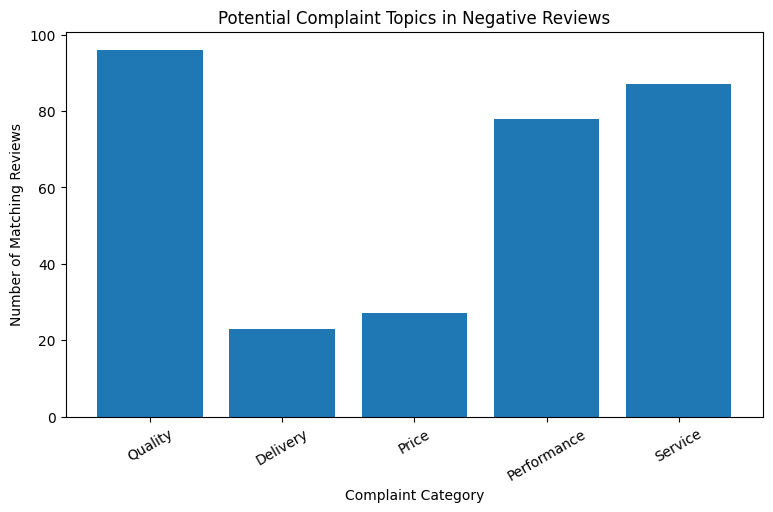

In [ ]:

plt.figure(figsize=(9, 5))

plt.bar(
    complaints_df["Category"],
    complaints_df["Review Count"]
)

plt.title("Potential Complaint Topics in Negative Reviews")
plt.xlabel("Complaint Category")
plt.ylabel("Number of Matching Reviews")
plt.xticks(rotation=30)

plt.show()


In [ ]:

from google.colab import files

with pd.ExcelWriter(
    "Amazon_Reviews_NLP_Analysis.xlsx"
) as writer:

    df.to_excel(
        writer,
        sheet_name="Reviews",
        index=False
    )

    top_words.to_excel(
        writer,
        sheet_name="Frequent Negative Words",
        index=False
    )

    complaints_df.to_excel(
        writer,
        sheet_name="Complaint Topics",
        index=False
    )

files.download("Amazon_Reviews_NLP_Analysis.xlsx")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>